In [6]:
from pathlib import Path

import numpy as np

arepo_path = Path("remnant_Model_1696_Explosion108_new.txt")
output_path = Path("remnant_composition_MESA22.dat")

MESA22 = [
    "neut", "h1", "prot", "he3", "he4", "c12", "n14", "o16", "ne20", "mg24",
    "si28", "s32", "ar36", "ca40", "ti44", "cr48", "cr56", "fe52", "fe54",
    "fe56", "co56", "ni56",
]


def write_mesa22_composition(arepo_path, output_path):
    arepo_path = Path(arepo_path)
    output_path = Path(output_path)
    
    with arepo_path.open() as profile:
        for line in profile:
            if line.startswith("# r_inner,"):
                columns = [name.strip() for name in line[1:].split(",")]
                break
        else:
            raise ValueError("Could not find the AREPO column header.")

        data = np.loadtxt(profile, ndmin=2)

    if len(columns) != data.shape[1] or len(set(columns)) != len(columns):
        raise ValueError("The AREPO header does not match the data columns.")

    mass = data[:, columns.index("mass")]
    radius = data[:, columns.index("r_outer")]
    if not np.all(np.isfinite(mass) & (mass > 0)):
        raise ValueError("Expected finite, positive shell masses.")
    if not np.all(np.isfinite(radius)) or not np.all(np.diff(radius) > 0):
        raise ValueError("Expected AREPO shells in center-to-surface order.")

    # AREPO uses n and p for free neutrons and protons.
    aliases = {"n": "neut", "p": "prot"}
    abundances = {}
    for column, values in zip(columns, data.T):
        if column.startswith("xn_"):
            isotope = column[3:]
            abundances[aliases.get(isotope, isotope)] = values

    if not abundances:
        raise ValueError("No AREPO abundance columns were found.")
    source_fractions = np.column_stack(list(abundances.values()))
    if (
        not np.all(np.isfinite(source_fractions))
        or np.any(source_fractions < 0)
        or not np.allclose(source_fractions.sum(axis=1), 1.0, atol=1e-6, rtol=0)
    ):
        raise ValueError("Expected finite, nonnegative AREPO fractions summing to one.")

    # Fill absent MESA isotopes with zero, then renormalize the retained species.
    zeros = np.zeros_like(mass)
    composition = np.column_stack([abundances.get(name, zeros) for name in MESA22])
    retained = composition.sum(axis=1)
    if np.any(retained <= 0):
        raise ValueError("At least one shell has no abundance in MESA22.")
    composition /= retained[:, None]

    # The relaxation file runs from surface to center using shell-midpoint q.
    surface_first_mass = mass[::-1]
    q = (np.cumsum(surface_first_mass) - 0.5 * surface_first_mass) / mass.sum()
    table = np.column_stack([q, composition[::-1]])

    # Exclusive creation protects an existing output file.
    with output_path.open("x") as output:
        output.write(f"{len(mass)}\t{len(MESA22)}\n")
        for coordinate, *fractions in table:
            fields = [f"{coordinate:.17E}", *(f"{x:.10E}" for x in fractions)]
            output.write("\t".join(fields).replace("E", "D") + "\n")

    omitted = source_fractions.sum(axis=1) - retained
    print(f"Wrote {len(mass)} shells and {len(MESA22)} isotopes to {output_path}")
    print(f"Omitted mass fraction: {np.average(omitted, weights=mass):.6%}")

arepo_path = "/afs/mpa/temp/abinaya3/HVs/remnant_Model_1696_Explosion108_new.txt"
write_mesa22_composition(arepo_path, output_path)

Wrote 1000 shells and 22 isotopes to remnant_composition_MESA22_from_notebook.dat
Omitted mass fraction: 0.001089%


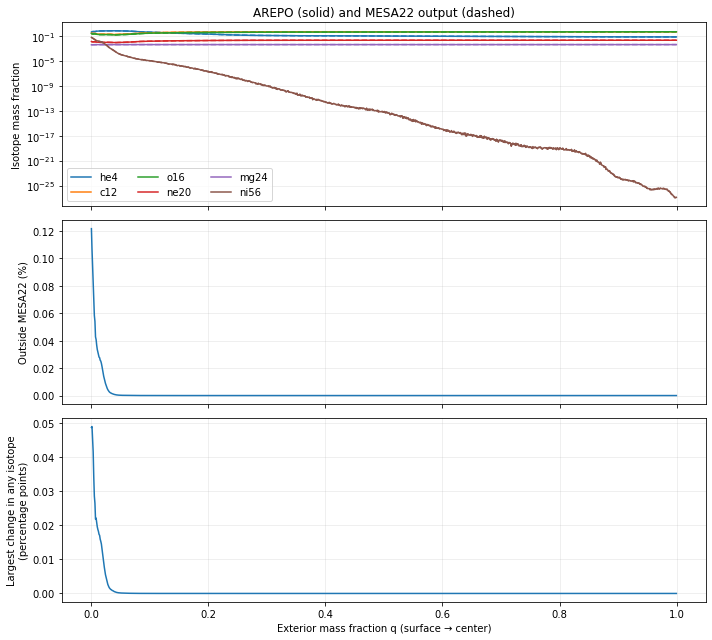

Max |sum(X_MESA) - 1|: 1.42e-11
Omitted fraction across the remnant: 0.001089%
Largest abundance change: he4 at q=0.001501, +0.049059 percentage points
Top omitted isotopes by mass:
  ni58: 0.00100798% of the remnant
  ni59: 7.26068e-05% of the remnant
  al25: 4.16501e-06% of the remnant
  f18: 1.50793e-06% of the remnant
  n13: 8.82615e-07% of the remnant


In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Reuse arepo_path, output_path, and MESA22 from the conversion cell.
with Path(arepo_path).open() as profile:
    for line in profile:
        if line.startswith("# r_inner,"):
            columns = [name.strip() for name in line[1:].split(",")]
            break
    else:
        raise ValueError("Could not find the AREPO column header.")

    arepo = np.loadtxt(profile, ndmin=2)[::-1]  # Surface first

aliases = {"n": "neut", "p": "prot"}
original = {
    aliases.get(name[3:], name[3:]): arepo[:, i]
    for i, name in enumerate(columns)
    if name.startswith("xn_")
}

# Read the actual file, including its Fortran D exponents.
with Path(output_path).open() as profile:
    n_shells, n_isotopes = map(int, next(profile).split())
    mesa = np.loadtxt(
        (line.replace("D", "E").replace("d", "e") for line in profile),
        ndmin=2,
    )

mass = arepo[:, columns.index("mass")]
q_arepo = (np.cumsum(mass) - 0.5 * mass) / mass.sum()
q = mesa[:, 0]
written = mesa[:, 1:]

assert n_isotopes == len(MESA22)
assert mesa.shape == (n_shells, n_isotopes + 1)
np.testing.assert_allclose(q, q_arepo, rtol=0, atol=1e-12)

omitted = {
    name: values for name, values in original.items() if name not in MESA22
}
omitted_fraction = sum(omitted.values(), np.zeros_like(mass))

# Percentage-point change in each isotope, compared shell by shell.
original_retained = np.column_stack([
    original.get(name, np.zeros_like(mass)) for name in MESA22
])
change_pp = 100 * (written - original_retained)
largest_change_pp = np.max(np.abs(change_pp), axis=1)

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

for name in ["he4", "c12", "o16", "ne20", "mg24", "ni56"]:
    i = MESA22.index(name)
    before = original_retained[:, i]
    after = written[:, i]
    line, = axes[0].plot(
        q, np.where(before > 0, before, np.nan), label=name
    )
    axes[0].plot(
        q, np.where(after > 0, after, np.nan),
        "--", color=line.get_color(),
    )

axes[0].set_yscale("log")
axes[0].set_ylabel("Isotope mass fraction")
axes[0].set_title("AREPO (solid) and MESA22 output (dashed)")
axes[0].legend(ncol=3)

axes[1].plot(q, 100 * omitted_fraction)
axes[1].set_ylabel("Outside MESA22 (%)")

axes[2].plot(q, largest_change_pp)
axes[2].set_ylabel("Largest change in any isotope\n(percentage points)")
axes[2].set_xlabel("Exterior mass fraction q (surface → center)")

for ax in axes:
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

shell, isotope = np.unravel_index(
    np.abs(change_pp).argmax(), change_pp.shape
)
print("Max |sum(X_MESA) - 1|: {:.2e}".format(
    np.max(np.abs(written.sum(axis=1) - 1))
))
print("Omitted fraction across the remnant: {:.6%}".format(
    np.average(omitted_fraction, weights=mass)
))
print("Largest abundance change: {} at q={:.6f}, {:+.6f} percentage points".format(
    MESA22[isotope], q[shell], change_pp[shell, isotope]
))
print("Top omitted isotopes by mass:")
for name, values in sorted(
    omitted.items(), key=lambda item: np.dot(item[1], mass), reverse=True
)[:5]:
    print("  {}: {:.6g}% of the remnant".format(
        name, 100 * np.average(values, weights=mass)
    ))